### Create a Sequential model that will contain our augmentation layers
- The 'RandomFlip' layer is not ideal for traffic signs, as flipping a 'turn right' sign horizontally would make it a 'turn left' sign,which is incorrect.
- Randomly rotate the image by a certain factor. A factor of 0.1 means the rotation will be in the range [-10% * 360, +10% * 360] degrees, which is [-36, 36] degrees. Let's use a smaller, more realistic range. A factor of 0.1 means rotation in the range [-10% * 2*pi, 10% * 2*pi] radians which is roughly [-36, 36] degrees. Let's use a smaller value, e.g., 10 degrees. So we'll use a factor of 10/360 = ~0.03
- Randomly zoom into or out of the image. A factor of 0.1 means the zoom will be in the range [90%, 110%] of the original size.
- Randomly change the brightness of the image. A factor of 0.2 means the brightness will be randomly adjusted in the range [80%, 120%] of the original. This simulates different lighting conditions.
- Add a small amount of translation

In [1]:
import sys
sys.path.append('../src')
from data.data_loader import load_gtsrb_data
from tensorflow.keras.utils import to_categorical

X_train, y_train, X_test, y_test = load_gtsrb_data('../data/processed')
num_classes = 43
y_train_one_hot = to_categorical(y_train, num_classes=num_classes)
y_test_one_hot  = to_categorical(y_test,  num_classes=num_classes)

2026-11-21 00:47:48.334842: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Loading Test.csv: 100%|██████████| 12630/12630 [00:05<00:00, 2412.82it/s]


✅ Data loading, resizing, and grayscaling complete.
Training images shape: (39209, 32, 32, 1), Labels shape: (39209,)
Test images shape: (12630, 32, 32, 1), Labels shape: (12630,)


In [2]:
from sklearn.model_selection import train_test_split

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train_one_hot,
    test_size=0.2,                          # 20% validation
    stratify=y_train_one_hot.argmax(axis=1),
    random_state=42
)


In [3]:
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

# X_train.shape (39209, 32, 32, 1)
# Define the Data Augmentation Pipeline ---
# Create a Sequential model that will contain augmentation layers.
ROTATION_FACTOR = 0.08
ZOOM_FACTOR = 0.1
BRIGHTNESS_FACTOR = 0.2
data_augmentation = Sequential(
    [
        layers.RandomRotation(factor=ROTATION_FACTOR, fill_mode='nearest'), # Rotates between -18 and +18 degrees
        layers.RandomZoom(height_factor=ZOOM_FACTOR, width_factor=ZOOM_FACTOR, fill_mode='nearest'),
        layers.RandomBrightness(factor=BRIGHTNESS_FACTOR, value_range=(0.0, 1.0)),
        layers.RandomTranslation(height_factor=0.1, width_factor=0.1, fill_mode='nearest'),
    ],
    name="data_augmentation"
)

data_augmentation.summary()

Model: "data_augmentation"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_rotation                 │ ?                      │   0 (unbuilt) │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_brightness               │ ?                      │   0 (unbuilt) │
│ (RandomBrightness)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ ?                      │   0 (unbuilt) │
│ (RandomTranslation)             │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [4]:
def visualize_augmentations(dataset, augmenter, num_images=9):
    """
    Takes a single image from a dataset and visualizes the effect
    of the augmentation pipeline on it.

    Args:
        dataset (np.array): The training dataset (e.g., X_train).
        augmenter (tf.keras.Model): The Sequential model containing augmentation layers.
        num_images (int): The number of augmented examples to display.
    """
    # Take one random image from the dataset
    idx = np.random.randint(0, len(dataset))
    image = dataset[idx]
    # Original shape: (32, 32, 1) -> New shape: (1, 32, 32, 1)
    image_batched = tf.expand_dims(image, 0)
    grid_size = int(np.sqrt(num_images))
    plt.figure(figsize=(10, 10))
    plt.subplot(grid_size + 1, grid_size, 1)
    plt.imshow(tf.squeeze(image), cmap='gray')
    plt.title("Original")
    plt.axis('off')

    # Generate and display augmented images
    for i in range(num_images):
        augmented_image = augmenter(image_batched, training=True)
        plt.subplot(grid_size + 1, grid_size, i + 2)
        # The output is a batch, so we squeeze to remove the batch dim for display
        plt.imshow(tf.squeeze(augmented_image), cmap='gray')
        plt.axis('off')

    plt.suptitle(f"Final Augmentation Check (Original Image {idx})", fontsize=16)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

--- Visualization 1 ---


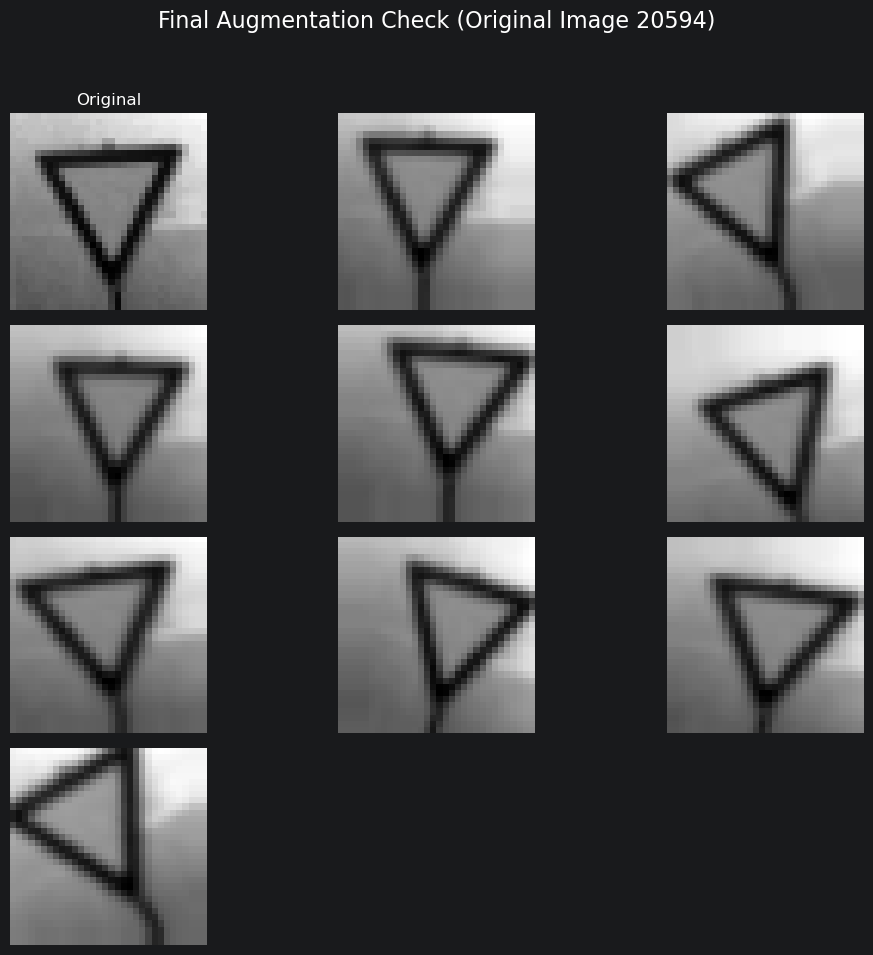


--- Visualization 2 ---


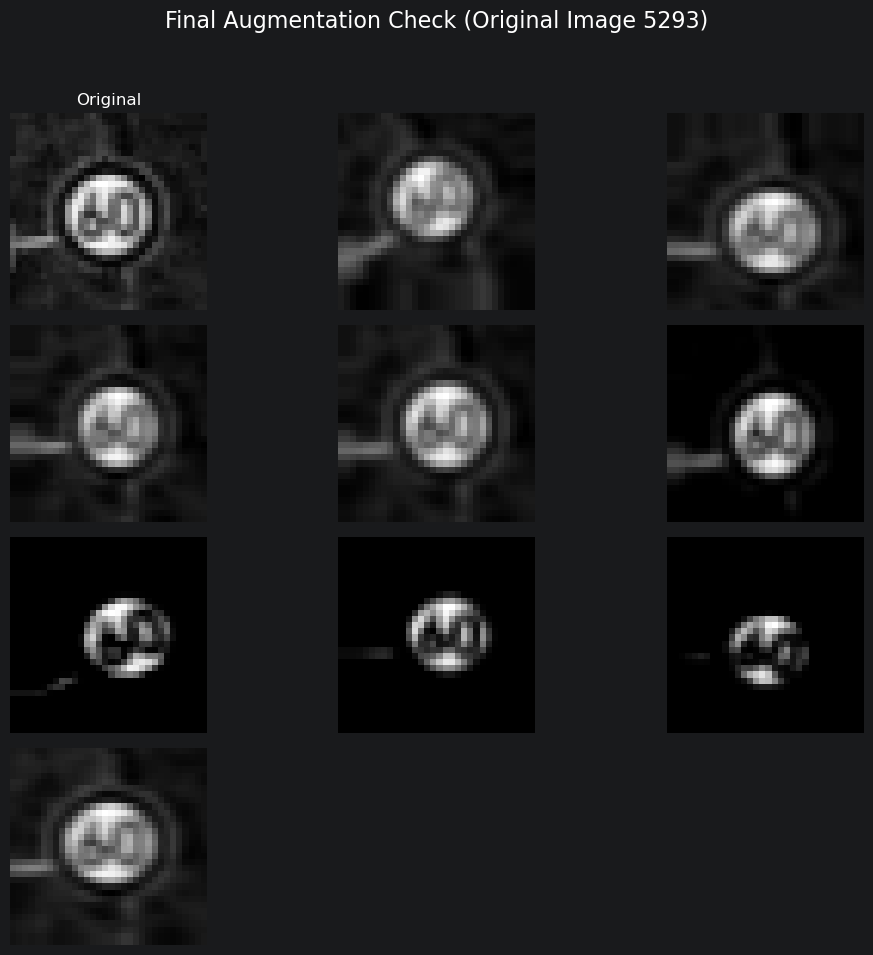

In [5]:
print("--- Visualization 1 ---")
visualize_augmentations(X_train, data_augmentation, num_images=9)

print("\n--- Visualization 2 ---")
visualize_augmentations(X_train, data_augmentation, num_images=9)

In [6]:
from tensorflow.keras import Input

INPUT_SHAPE = X_train.shape[1:]
NUM_CLASSES = y_train_one_hot.shape[1]

model = Sequential(
    [
    Input(shape=INPUT_SHAPE),
    data_augmentation,
    Conv2D(filters=32, kernel_size=(3, 3), activation='relu'),
    MaxPooling2D(
        pool_size=(2, 2)  # The size of the window to slide over the feature map.
    ),
      # Second Convolutional Layer
    Conv2D(
        filters=64,             # We increase the number of filters to learn more complex patterns.
        kernel_size=(3, 3),     # A 3x3 kernel remains effective.
        activation='relu'       # ReLU continues to be our go-to activation function.

    ),
    # Second Max Pooling Layer
    MaxPooling2D(pool_size=(2, 2)),  # We downsample again to reduce dimensionality.
    # into a 1D feature vector.
    Flatten(),
    Dense(
        units=512,            # The number of neurons in the layer, a key hyperparameter.
        activation='relu'     # ReLU continues to be the best choice for hidden layers.
    ),
    Dropout(
        rate=0.5  # The fraction of the input units to drop. 0.5 is a common choice.
    ),
     Dense(
        units=NUM_CLASSES,      # The number of output neurons, one for each traffic sign class (43).
        activation='softmax'  # Softmax ensures the output is a probability distribution.
    )
], name="TrafficSign_Classifier_with_Augmentation")
model.compile(
    optimizer='adam',                               # The algorithm to use for updating weights.
    loss='categorical_crossentropy',                # The function to measure how wrong the model is.
    metrics=['accuracy']                            # A list of metrics to monitor during training.
)
print("--- Starting Model Training ---")
EPOCHS = 20
BATCH_SIZE = 64

history = model.fit(
    X_tr,
    y_tr,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    validation_data=(X_val, y_val)
)

print("--- Model Training Complete ---")

--- Starting Model Training ---
Epoch 1/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 27s 50ms/step - accuracy: 0.2724 - loss: 2.6782 - val_accuracy: 0.6702 - val_loss: 1.1903
Epoch 2/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 24s 48ms/step - accuracy: 0.5194 - loss: 1.6267 - val_accuracy: 0.8022 - val_loss: 0.6881
Epoch 3/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 21s 43ms/step - accuracy: 0.6102 - loss: 1.2963 - val_accuracy: 0.8600 - val_loss: 0.4935
Epoch 4/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 21s 44ms/step - accuracy: 0.6729 - loss: 1.0813 - val_accuracy: 0.8957 - val_loss: 0.3679
Epoch 5/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 24s 48ms/step - accuracy: 0.7113 - loss: 0.9503 - val_accuracy: 0.9116 - val_loss: 0.3029
Epoch 6/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 22s 45ms/step - accuracy: 0.7429 - loss: 0.8506 - val_accuracy: 0.9314 - val_loss: 0.2399
Epoch 7/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 23s 47ms/step - accuracy: 0.7619 - loss: 0.7717 - val_accuracy: 0.9467 - val_loss: 0.1942
Epoch 8/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 26s 52ms/step - ac

In [7]:
from pathlib import Path

models_dir = Path("models")
models_dir.mkdir(exist_ok=True)

# Save in native Keras format (.keras)
keras_model_path = models_dir / "traffic_sign_classifier.keras"
print(f"Saving model to: {keras_model_path}")
model.save(keras_model_path)
print("✅ Model saved successfully in .keras format.")

# Save in TensorFlow SavedModel format
savedmodel_path = models_dir / "traffic_sign_classifier_savedmodel"
print(f"\nSaving model to directory: {savedmodel_path}")
model.export(savedmodel_path)
print("✅ Model saved successfully in SavedModel format.")

Saving model to: models/traffic_sign_classifier.keras
✅ Model saved successfully in .keras format.

Saving model to directory: models/traffic_sign_classifier_savedmodel
INFO:tensorflow:Assets written to: models/traffic_sign_classifier_savedmodel/assets


INFO:tensorflow:Assets written to: models/traffic_sign_classifier_savedmodel/assets


Saved artifact at 'models/traffic_sign_classifier_savedmodel'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 32, 32, 1), dtype=tf.float32, name='keras_tensor_5')
Output Type:
  TensorSpec(shape=(None, 43), dtype=tf.float32, name=None)
Captures:
  4840664208: TensorSpec(shape=(), dtype=tf.resource, name=None)
  6344207120: TensorSpec(shape=(), dtype=tf.resource, name=None)
  6344208080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  6344208272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  6406319248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  6406324048: TensorSpec(shape=(), dtype=tf.resource, name=None)
  6406322512: TensorSpec(shape=(), dtype=tf.resource, name=None)
  6406322704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  6406323472: TensorSpec(shape=(), dtype=tf.resource, name=None)
  6414778640: TensorSpec(shape=(), dtype=tf.resource, name=None)
  6414779984: TensorSpec(shape=(), dtype

In [8]:
import pickle
with open('models/training_history.pkl', 'wb') as f:
    pickle.dump(history.history, f)